# T1.2 Doppler

**Purpose** (Table 4.2, D-5 validation plan): similar to T1.1 NRCS, but for Doppler. The (non-current) wave Doppler generated by the SWB,
integrated over the SCA beam and low-pass filtered (LPF), is compared to the wave Doppler expected from a conventional Doppler Geophysical Model Function (GMF).

**Implementation**
1. Estimate SCA-Dop from SWB: NRCS-weighted azimuthal beam integration of the SWB wave Doppler with the EUMETSAT beam pattern
2. LPF SCA-Dop and the SWB wind field to the product resolution (50 km)
3. Estimate GMF Dop from the LPF SWB wind field, with CDOP (Mouche et al., 2012)
4. Compare GMF Dop with LPF SCA-Dop

**Requirements**: reference simulations SWB-SCA (California, MED-1, MED-2), Doppler GMF (CDOP)

This notebook performs the test and reports the results for interpretation. No tolerances or pass/fail criteria are applied.

**Notes**
- Only the wave Doppler (`wave_dop`) is integrated, since CDOP contains no surface current.
- 50 km is the product resolution (about one independent sample per 25 km).
- The SWB (stress-equivalent) wind is used as the CDOP input.
- Wind direction: `wdir_wrt_sensor` = 0 is the wind blowing away from the sensor (GMF_SWB convention). CDOP's $\phi$ = 0 is upwind,
  i.e. the wind blowing towards the radar, so $\phi$ = `wdir_wrt_sensor` + 180.
- CDOP was derived from ENVISAT ASAR (5.331 GHz). Its Doppler is converted to the SCA carrier frequency (5.405 GHz) by the ratio of the frequencies,
  i.e. the line-of-sight velocity is kept (a 1.4 % change).

In [1]:
import numpy as np
import xarray as xr
import pandas as pd
from matplotlib import pyplot as plt

from sca_module.readers import create_dataset
from sca_module.dopsca_setup import DopSCAConfig
from sca_module.simulate_L1 import compute_cube_observation_geometry, compute_observations, create_observation_cube, compute_lpf_cube
from leakage.conversions import angular_difference, dir_from_u_v, magnitude_from_u_v, convert_to_0_360
from stereoid.oceans.forward_models.cdop import cdop

func_bias = lambda x, rounding=3:  np.round(np.nanmean(x), rounding)

plt.rcParams.update({'font.size': 10, 'font.weight' : 'bold'})

# Data preparation
## 0 - Parameters

In [2]:
sca = DopSCAConfig()
sca.Lambda = sca.get_wavelength()
# The magic_divider is an unnecessary, but convenient, method to resample the input data to some common sampling.
# This prevents aliasing in azimuth, and does not remove range resolution
sca.grid_spacing_target = sca.get_grid_spacing_target(magic_divider=2)

f0_ASAR = 5.331e9 # ENVISAT ASAR carrier frequency [Hz], on which CDOP was derived

## 1 - Load SWB simulations

In [3]:
files = {
    "California": [
        '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_input_California.nc',
        '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_output_California.nc'
    ],
    "MED-1": [
        '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_input_med_orb70_2022-01-20T18.nc',
        '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_output_med_orb70_2022-01-20T18.nc'
    ],
    "MED-2": [
        '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_input_med_orb70_2022-01-22T18.nc',
        '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_output_med_orb70_2022-01-22T18.nc'
    ],
}

# California is kept over its full swath. The Mediterranean cases are cropped to avoid the regions where the SWB fails (NaN NRCS),
# as in SCA_uncertainty___monte_carlo_MED.ipynb
domains = {
    "California": dict(),
    "MED-1": dict(grg = slice(590E3, 742E3), az = slice(50E3, 350E3)),
    "MED-2": dict(grg = slice(590E3, 742E3), az = slice(50E3, 350E3)),
}

# reload interpolated beam pattern received from EUMETSAT
beam_SCA = xr.open_dataset('/Users/opodriscoll/Documents/projects/DopSCA MOMS/data/beam_pattern_updated.nc')['beam_sca']

In [4]:
simulations = {}
for case in files:
    simulation = xr.open_mfdataset(files[case], compat='no_conflicts', engine='netcdf4').sel(sat = 'S1').drop_vars('bist_ang').compute()
    sca.magic_offset = sca.get_magic_offset(incidence_min=simulation.inc.min().data)

    # clipping unreasonable incidence angles
    simulation = simulation.sel(grg = slice(sca.grg_min - sca.magic_offset, sca.grg_max - sca.magic_offset))
    simulation = simulation.assign_coords(grg = simulation.grg + sca.magic_offset)

    # Here we interpolate to finer grid spacing,
    new_az = np.arange(simulation.az.min(), simulation.az.max(), sca.grid_spacing_target)
    new_grg = np.arange(simulation.grg.min(), simulation.grg.max(), sca.grid_spacing_target)
    simulation = simulation.interp(az=new_az, grg=new_grg)
    simulation = simulation.sel(domains[case])

    # wind speed and direction w.r.t. the sensor at the native resolution
    # 0 & 360 is blowing away from the sensor, 180 is blowing towards (convention of GMF_SWB)
    simulation['wspd'] = magnitude_from_u_v(u=simulation['wnd_u'], v=simulation['wnd_v'])
    simulation['wdir'] = dir_from_u_v(u=simulation['wnd_u'], v=simulation['wnd_v'])
    sensor_dir = 90 # assuming right looking
    simulation['wdir_wrt_sensor'] = convert_to_0_360(angular_difference(sensor_dir, np.rad2deg(simulation['wdir'])))

    simulations[case] = simulation

## 2 - CDOP and its wind-direction convention
CDOP's $\phi$ is the wind direction relative to the radar look direction, with $\phi$ = 0 upwind (wind blowing towards the radar) and a positive Doppler for motion towards the radar.

In [5]:
def cdop_vv(wspd, wdir_wrt_sensor, inc, phi_offset = 180):
    """
    CDOP VV wave Doppler [Hz] at the SCA carrier frequency for xarray inputs, broadcast against each other

    wdir_wrt_sensor follows the GMF_SWB convention (0 is blowing away from the sensor), inc is in degrees.
    CDOP's phi = 0 is the wind blowing towards the radar, hence the default phi_offset of 180 degrees.
    The Doppler is scaled from the ASAR to the SCA carrier frequency, keeping the line-of-sight velocity
    """
    wspd, phi, inc = xr.broadcast(wspd, convert_to_0_360(wdir_wrt_sensor + phi_offset), inc)
    dop = cdop(wspd.to_numpy().ravel(), phi.to_numpy().ravel(), inc.to_numpy().ravel(), 'VV').astype(float) * sca.f0 / f0_ASAR
    dop = xr.DataArray(dop.reshape(wspd.shape), dims=wspd.dims, coords=wspd.coords)
    return dop.where(wspd.notnull() & phi.notnull())

## 3 - Estimate SCA-Dop from SWB (step 1)
NRCS-weighted beam integration of the SWB wave Doppler along azimuth with the EUMETSAT beam pattern: `dop_pulse_rg`. The SWB wave Doppler is passed as `dop`,
so `compute_observations` weights it with the (noise-free) SWB NRCS and the beam.

In [6]:
VARS_SCA = ["dop_pulse_rg", "nrcs_scat", "inc_scat"]

observations = {}
for case, simulation in simulations.items():
    nrcs = simulation[sca.var_nrcs].sel(pol='M')
    dop = simulation['wave_dop'].sel(pol='M')
    inc_2d = np.degrees(simulation[sca.var_inc].expand_dims(dim={sca.dim_az: simulation.az.data}))

    data = create_dataset(
        nrcs=nrcs.data,
        dop=dop.data,
        inc=inc_2d.data,
        grg=simulation.grg.data,
        az=simulation.az.data,
        grid_spacing=sca.grid_spacing_target,
    )

    data_cube = create_observation_cube(data, sca.az_footprint_cutoff, sca.grid_spacing_target, sca.v_sat_ground, sca.PRF, dropna=False).compute()
    data_cube = compute_cube_observation_geometry(data_cube, sca.dim_az_beam, sca.dim_az_slow_time, sca.dim_range, sca.var_inc, sca.z0, sca.boresight_elevation_angle_scat)

    data_cube = data_cube.transpose(sca.dim_az_slow_time, sca.dim_az_beam, sca.dim_range)
    data_cube['beam']= beam_SCA.interp(az_beam=data_cube.az_beam, grg=data_cube.grg, method='linear')

    data_cube = compute_observations(data_cube, sca.var_nrcs, sca.var_inc, sca.dim_az_beam, sca.v_sat_orbit, sca.Lambda, sca.T_pp, var_azimuth_angle_wrt_boresight = "az_angle_wrt_boresight_ground")

    # only the beam-integrated fields are kept, the cube itself is large
    observations[case] = data_cube[VARS_SCA].transpose(sca.dim_az_slow_time, sca.dim_range).compute()
    observations[case].attrs["stride"] = data_cube.attrs["stride"]

## 4 - LPF SCA-Dop to the product resolution (step 2)

In [7]:
for case, obs in observations.items():
    observations[case] = compute_lpf_cube(
        obs,
        resolution_product= sca.resolution_product,
        fs_x=1 / obs.attrs["stride"],
        fs_y=1 / sca.grid_spacing_target,
        data_2_lpf=["dop_pulse_rg"],
        window=sca.product_averaging_window,
        crop_edges = True,
        min_footprint_coverage = 1, # only product cells whose whole footprint is available
    )

## 5 - LPF SWB wind field to the product resolution (step 2)
The wind is filtered over the same azimuthal extent as the SCA Doppler. The beam integration shortens that extent by the footprint (+- 40 km),
and near the edges the filter only averages over the available samples, so both fields must share the same edges.

In [8]:
for case, simulation in simulations.items():
    # crop to the azimuthal extent of the SCA observations, which the beam integration shortens by the footprint.
    # Near the edges the filter only averages over the available samples, so both fields must share the same edges
    az_sca, stride = observations[case][sca.dim_az_slow_time], observations[case].attrs["stride"]
    simulation = simulation.sel({sca.dim_az: slice(az_sca.min().item() - stride / 2, az_sca.max().item() + stride / 2)})

    data_2_lpf : list[str] = ["wnd_u", "wnd_v"]
    names_lpf_vars = [i+'_lpf' for i in data_2_lpf]
    coords_to_drop = (set(simulation.coords) - set(list(simulation[data_2_lpf[0]].dims)))

    # NOTE fs_x is the sampling along the first dimension (az), fs_y along the second (grg)
    simulation[names_lpf_vars] = compute_lpf_cube(
        ds_cube = simulation.drop_vars(coords_to_drop)[data_2_lpf],
        fs_x = 1 / sca.grid_spacing_target,
        fs_y = 1 / sca.grid_spacing_target,
        resolution_product = sca.resolution_product,
        data_2_lpf = data_2_lpf,
        window = sca.product_averaging_window,
        crop_edges = True,
        min_footprint_coverage = 1, # only product cells whose whole footprint is available
    )[names_lpf_vars]

    simulation['wspd_lpf'] = magnitude_from_u_v(u=simulation['wnd_u_lpf'], v=simulation['wnd_v_lpf'])
    simulation['wdir_lpf'] = dir_from_u_v(u=simulation['wnd_u_lpf'], v=simulation['wnd_v_lpf'])
    simulation['wdir_wrt_sensor_lpf'] = convert_to_0_360(angular_difference(sensor_dir, np.rad2deg(simulation['wdir_lpf'])))
    simulations[case] = simulation

## 6 - Estimate GMF Dop (step 3)
CDOP of the LPF SWB wind, on the SCA product grid.

In [9]:
comparisons = {}
for case, simulation in simulations.items():
    obs = observations[case]

    on_sca_grid = simulation[['wspd_lpf', 'wdir_wrt_sensor_lpf']].reset_coords(drop=True).interp(
        {sca.dim_az: obs[sca.dim_az_slow_time], sca.dim_range: obs[sca.dim_range]}
    )

    comparison = xr.Dataset({
        "dop_sca": obs['dop_pulse_rg_lpf'],
        "dop_cdop": cdop_vv(on_sca_grid['wspd_lpf'], on_sca_grid['wdir_wrt_sensor_lpf'], obs['inc_scat']),
        "inc": obs['inc_scat'],
    })

    # both fields are evaluated over the same product cells
    evaluate = comparison['dop_sca'].notnull() & comparison['dop_cdop'].notnull()
    comparisons[case] = comparison.where(evaluate)

## 7 - Compare GMF Dop with LPF SCA-Dop (step 4)
Difference in Hz: SCA - CDOP(LPF wind)

In [10]:
for case, comparison in comparisons.items():
    comparison['diff'] = comparison['dop_sca'] - comparison['dop_cdop']

# Results
## Summary
Bias is the mean difference SCA - CDOP(LPF wind), in Hz.

In [11]:
summary = pd.DataFrame(
    {"bias [Hz]": [func_bias(comparison['diff']) for comparison in comparisons.values()]},
    index=pd.Index(list(comparisons), name="case"),
)
summary

,bias [Hz]
case,
California,-1.575
MED-1,0.785
MED-2,1.635


## Maps
LPF SCA wave Doppler, CDOP of the LPF wind, and their difference, on the product cells evaluated.

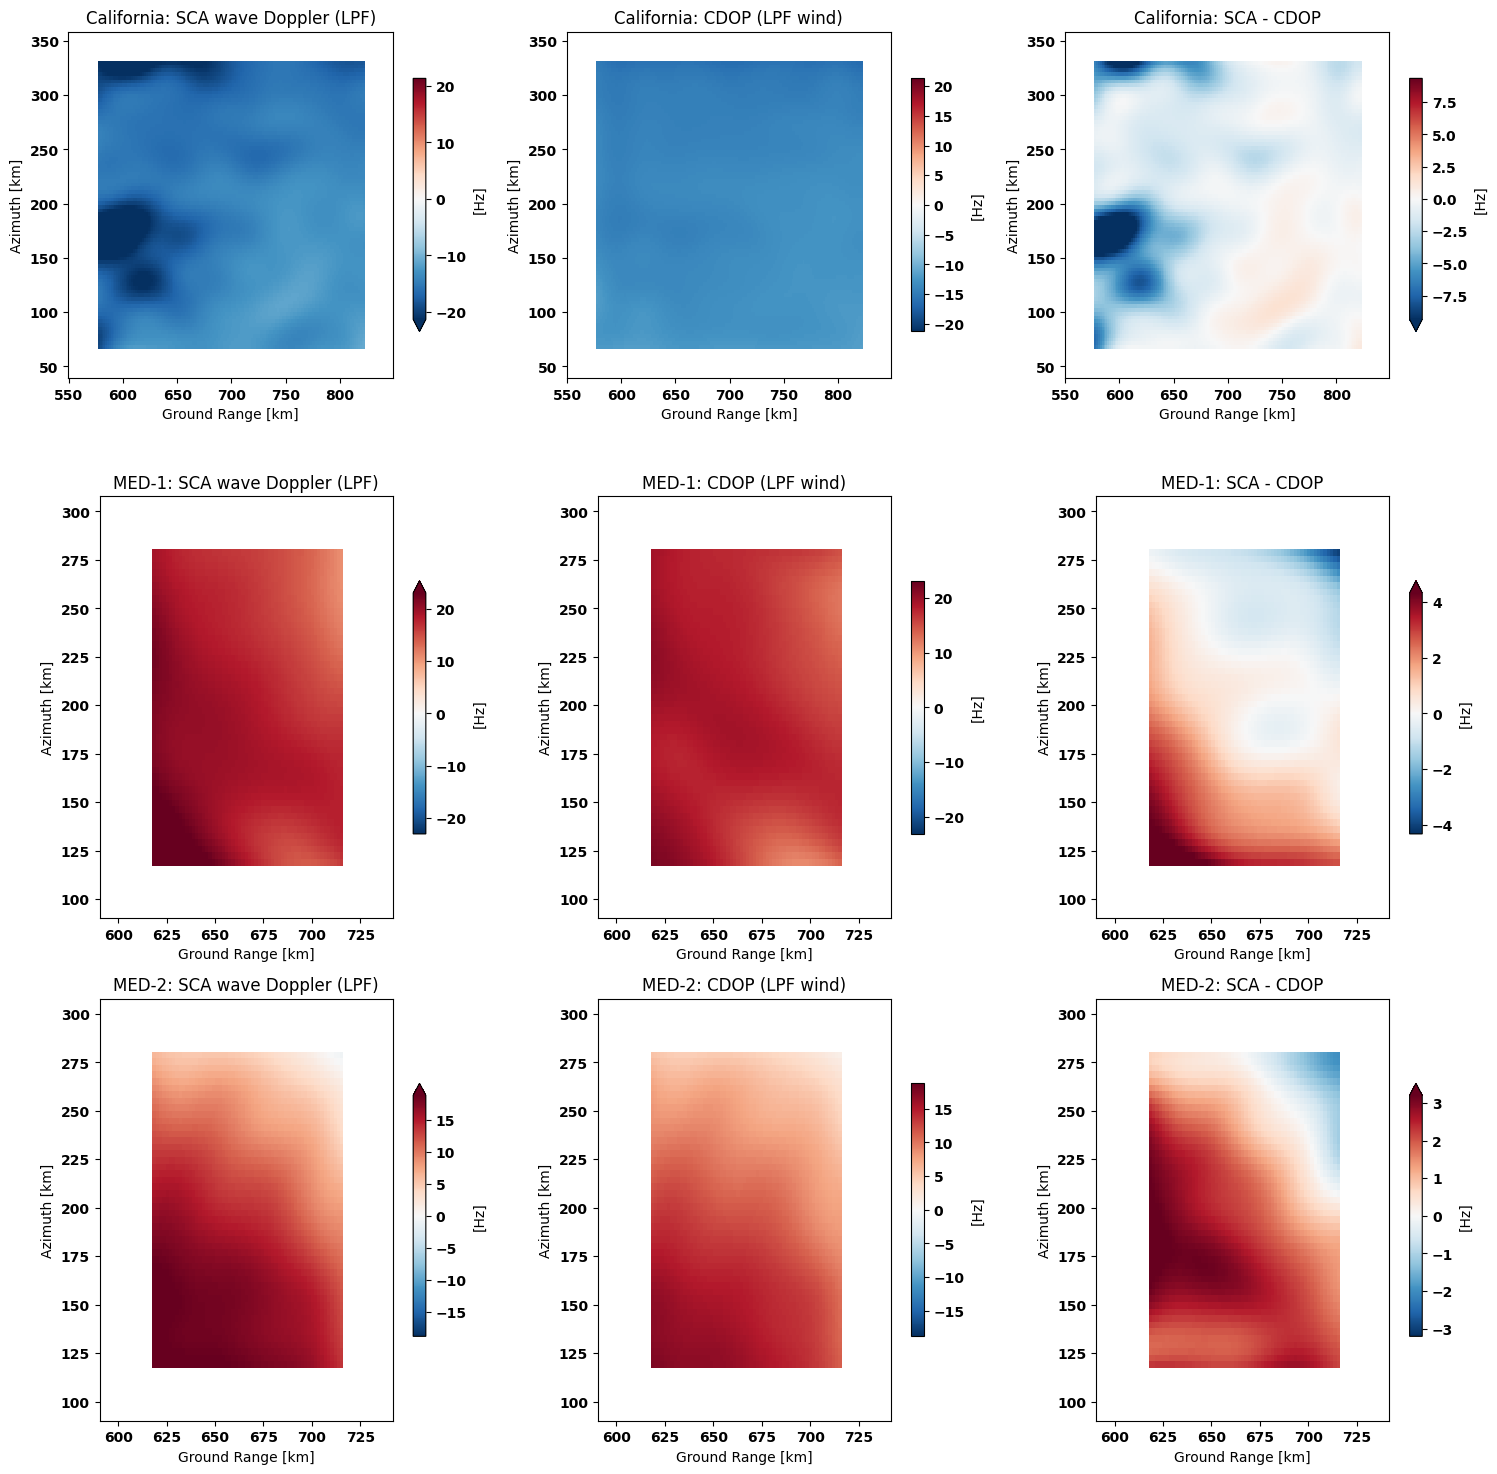

In [12]:
fig, axes = plt.subplots(ncols=3, nrows=len(comparisons), figsize = (15, 5 * len(comparisons)), squeeze=False)

for i, (case, comparison) in enumerate(comparisons.items()):
    c = comparison.assign_coords({sca.dim_range: comparison[sca.dim_range] / 1e3, sca.dim_az_slow_time: comparison[sca.dim_az_slow_time] / 1e3})
    lim = np.nanpercentile(abs(c[['dop_sca', 'dop_cdop']].to_array()), 98)
    c['dop_sca'].plot(ax = axes[i, 0], x=sca.dim_range, cmap = 'RdBu_r', vmin=-lim, vmax=lim, cbar_kwargs={"label": "[Hz]", "shrink" : 0.6})
    c['dop_cdop'].plot(ax = axes[i, 1], x=sca.dim_range, cmap = 'RdBu_r', vmin=-lim, vmax=lim, cbar_kwargs={"label": "[Hz]", "shrink" : 0.6})
    lim = np.nanpercentile(abs(c['diff']), 98)
    c['diff'].plot(ax = axes[i, 2], x=sca.dim_range, cmap = 'RdBu_r', vmin=-lim, vmax=lim, cbar_kwargs={"label": "[Hz]", "shrink" : 0.6})

    _ = axes[i, 0].set_title(f"{case}: SCA wave Doppler (LPF)")
    _ = axes[i, 1].set_title(f"{case}: CDOP (LPF wind)")
    _ = axes[i, 2].set_title(f"{case}: SCA - CDOP")

for ax in axes.flatten():
    ax.set_aspect('equal')
    ax.set_xlabel("Ground Range [km]")
    ax.set_ylabel("Azimuth [km]")
fig.tight_layout()